In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from keras import ops
import keras_hub

import kagglehub
import os
from pathlib import Path
import random

In [99]:
dataset_path = Path('D:/AI_TWO/NLP/Transformers/Machine Translation/Dataset')

english_file = dataset_path / 'english-corpus.txt'
urdu_file = dataset_path / 'urdu-corpus.txt'

for f in (english_file, urdu_file):
    print(f'{f.name}: {f.stat().st_size:>10,} bytes')

english-corpus.txt:    462,321 bytes
urdu-corpus.txt:    930,350 bytes


In [100]:
eng_lines = english_file.read_text(encoding = 'utf-8').splitlines()
urd_lines = urdu_file.read_text(encoding = 'utf-8').splitlines()

print(f'Number of lines in English file: {len(eng_lines):,}')
print(f'Number of lines in Urdu file: {len(urd_lines):,}')
print('-' * 80)

for i in range(6):
    print(f'EN: {eng_lines[i][:60]:<60} UR: {urd_lines[i]}')

Number of lines in English file: 24,525
Number of lines in Urdu file: 24,525
--------------------------------------------------------------------------------
EN: is zain your nephew                                          UR: زین تمہارا بھتیجا ہے۔
EN: i wish youd trust me                                         UR: کاش تم مجھ پر بھروسہ کرتے
EN: did he touch you                                             UR: کیا اس نے آپ کو چھوا؟
EN: its part of life                                             UR: اس کی زندگی کا حصہ
EN: zain isnt ugly                                               UR: زین بدصورت نہیں ہے۔
EN: above all be patient                                         UR: سب سے بڑھ کر صبر کرو


In [101]:
# Pair lines
pairs = [(e.strip(), u.strip()) for e,u in zip(eng_lines, urd_lines)]
print(f'Number of pairs before dropping empty lines: {len(pairs):,}')

# Drop empty lines
pairs = [(e,u) for e,u in pairs if e and u]
print(f'Number of pairs after dropping empty lines: {len(pairs):,}')

Number of pairs before dropping empty lines: 24,525
Number of pairs after dropping empty lines: 24,524


In [102]:
# Removing duplicated

duplicates = len(pairs)
pairs = list(dict.fromkeys(pairs))
print(f'Number of pairs after dropping duplicates: {len(pairs):,} (removed {duplicates - len(pairs):,} duplicates)')

Number of pairs after dropping duplicates: 24,138 (removed 386 duplicates)


In [103]:
# Removing misaligned lenght ratios

before = len(pairs)
pairs = [(e,u) for e,u in pairs if 1/3 <= len(e.split()) / max(len(u.split()), 1) <= 3]
print(f'Number of pairs after dropping misaligned length ratios: {len(pairs):,} (removed {before - len(pairs):,} pairs)')

Number of pairs after dropping misaligned length ratios: 24,123 (removed 15 pairs)


In [104]:
# Final Clean Dataset
print(f'Final Dataset: {len(pairs):,} pairs ({len(pairs)/24525:.0%} of original dataset)')

Final Dataset: 24,123 pairs (98% of original dataset)


In [105]:
#Splitting

random.Random(42).shuffle(pairs)

test = pairs[:1000]
val = pairs[1000:2000]
train = pairs[2000:]

print(f'Training pairs: {len(train):,}')
print(f'Validation pairs: {len(val):,}')
print(f'Test pairs: {len(test):,}')

Training pairs: 22,123
Validation pairs: 1,000
Test pairs: 1,000


In [106]:
# Count the number of words in each sentence of your dataset
source_texts = [english for english, _ in pairs]
sentence_lengths = [len(text.split()) for text in source_texts]

# Find the length that covers 95% of sentences
ideal_seq_length = int(np.percentile(sentence_lengths, 95))
print(f"Set SEQ_LENGTH to: {ideal_seq_length}")

Set SEQ_LENGTH to: 6


In [107]:
# Calculate the length of the longest sentence in each language
max_eng_sentence_length = max(len(text.split()) for text in english_file.read_text(encoding='utf-8').splitlines())
max_urdu_sentence_length = max(len(text.split()) for text in urdu_file.read_text(encoding='utf-8').splitlines())

print(f"Longest source sentence in English: {max_eng_sentence_length} words")
print(f"Longest target sentence in Urdu: {max_urdu_sentence_length} words")

Longest source sentence in English: 16 words
Longest target sentence in Urdu: 19 words


In [108]:
MAX_TOKENS = 8000
MAX_ENG_WORDS = 16
MAX_URD_WORDS = 19
SEQ_LENGTH = MAX_URD_WORDS + 2

In [109]:
source_vectorizer = keras.layers.TextVectorization(
    standardize = 'lower_and_strip_punctuation',
    max_tokens = MAX_TOKENS,
    output_mode = 'int',
    output_sequence_length = SEQ_LENGTH
)

target_vectorizer = keras.layers.TextVectorization(
    standardize = 'lower_and_strip_punctuation',
    max_tokens = MAX_TOKENS,
    output_mode = 'int',
    output_sequence_length = SEQ_LENGTH
)

In [110]:
# Build vocabulary

source_vectorizer.adapt([english for english, _ in train])
target_vectorizer.adapt(['startseq ' + urdu + ' endseq' for _, urdu in train])

english_vocab = source_vectorizer.get_vocabulary()
urdu_vocab = target_vectorizer.get_vocabulary()

print(f"English vocabulary size: {len(english_vocab):,}")
print(f"Urdu vocabulary size: {len(urdu_vocab):,}")
print('Most frequent Urdu tokens:', [str(t) for t in urdu_vocab[:10]])


English vocabulary size: 5,438
Urdu vocabulary size: 5,706
Most frequent Urdu tokens: ['', '[UNK]', 'startseq', 'endseq', 'میں', 'ہے', 'زین', 'نے', 'آپ', 'نہیں']


In [111]:
# Batch and teacher forcing

BATCH_SIZE = 64

def make_dataset(pairs, shuffle = False):
    english_texts = [english for english, _ in pairs]
    urdu_texts = [urdu for _, urdu in pairs]

    encoder_input = source_vectorizer(english_texts)
    decoder_input = target_vectorizer(['startseq ' + urdu for urdu in urdu_texts])
    decoder_output = target_vectorizer([urdu + ' endseq' for urdu in urdu_texts])

    dataset = tf.data.Dataset.from_tensor_slices(((encoder_input, decoder_input), decoder_output))

    if shuffle:
        dataset = dataset.shuffle(buffer_size = 4096, seed = 42)
    dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

In [112]:
train_dataset = make_dataset(train, shuffle = True)
val_dataset = make_dataset(val)

In [113]:
(enc_batch, dec_in_batch), dec_out_batch = next(iter(train_dataset))
print('ENGLISH INPUT :', ' '.join(english_vocab[t] for t in enc_batch[0].numpy() if t != 0))
print('DECODER INPUT :', ' '.join(urdu_vocab[t] for t in dec_in_batch[0].numpy() if t != 0))
print('TARGET OUTPUT :', ' '.join(urdu_vocab[t] for t in dec_out_batch[0].numpy() if t != 0))

ENGLISH INPUT : who likes beans
DECODER INPUT : startseq جو پھلیاں پسند کرتا ہے
TARGET OUTPUT : جو پھلیاں پسند کرتا ہے endseq


In [114]:
D_MODEL    = 128
NUM_HEADS  = 4
FF_DIM     = 512
NUM_LAYERS = 2
DROPOUT    = 0.1

ENG_V  = len(english_vocab)
URDU_V = len(urdu_vocab)

In [115]:
def build_transformer_model():
    encoder_inputs = keras.Input(shape = (None,), dtype = 'int64', name = 'encoder_inputs')
    decoder_inputs = keras.Input(shape = (None,), dtype = 'int64', name = 'decoder_inputs')

    encoder_mask = ops.not_equal(encoder_inputs, 0)
    decoder_mask = ops.not_equal(decoder_inputs, 0)

    # Encoder
    encoder_token_embeddings = keras.layers.Embedding(input_dim = ENG_V, output_dim = D_MODEL)(encoder_inputs)
    encoder_positional_embeddings = keras_hub.layers.PositionEmbedding(sequence_length = SEQ_LENGTH)(encoder_token_embeddings)
    x = layers.Add()([encoder_token_embeddings, encoder_positional_embeddings])
    x = layers.Dropout(DROPOUT)(x)


    for i in range(NUM_LAYERS):
        x = keras_hub.layers.TransformerEncoder(num_heads = NUM_HEADS, intermediate_dim = FF_DIM, dropout = DROPOUT)(x, padding_mask = encoder_mask)

    memoryview = x

    # Decoder
    decoder_token_embeddings = keras.layers.Embedding(input_dim = URDU_V, output_dim = D_MODEL)(decoder_inputs)
    decoder_positional_embeddings = keras_hub.layers.PositionEmbedding(sequence_length = SEQ_LENGTH)(decoder_token_embeddings)
    y = layers.Add()([decoder_token_embeddings, decoder_positional_embeddings])
    y = layers.Dropout(DROPOUT)(y)

    for i in range(NUM_LAYERS):
        y = keras_hub.layers.TransformerDecoder(num_heads = NUM_HEADS, intermediate_dim = FF_DIM, dropout = DROPOUT)(y, memoryview, decoder_padding_mask = decoder_mask, encoder_padding_mask = encoder_mask)

    # Output layer
    outputs = keras.layers.Dense(URDU_V, activation = 'softmax')(y)
    return keras.Model([encoder_inputs, decoder_inputs], outputs, name = 'transformer')

model = build_transformer_model()
model.summary()

Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_10        │ (None, None, 128) │    696,064 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding… │ (None, None, 128) │      2,688 │ embedding_10[0][… │
│ (PositionEmbedding) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_11        │ (None, None, 128) │    730,368 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, None, 128) │          0 │ embedding_10[0][… │
│                     │                   │            │ position_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding… │ (None, None, 128) │      2,688 │ embedding_11[0][… │
│ (PositionEmbedding) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_36          │ (None, None, 128) │          0 │ add_10[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_12        │ (None, None)      │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, None, 128) │          0 │ embedding_11[0][… │
│                     │                   │            │ position_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 128) │    198,272 │ dropout_36[0][0], │
│ (TransformerEncode… │                   │            │ not_equal_12[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_39          │ (None, None, 128) │          0 │ add_11[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 128) │    198,272 │ transformer_enco… │
│ (TransformerEncode… │                   │            │ not_equal_12[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_13        │ (None, None)      │          0 │ decoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decode… │ (None, None, 128) │    264,576 │ dropout_39[0][0], │
│ (TransformerDecode… │                   │            │ transformer_enco… │
│                     │                   │            │ not_equal_13[0][… │
│                     │                   │            │ not_equal_12[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decode… │ (None, None, 128) │    264,576 │ transformer_deco… │
│ (TransformerDecode… │                   │            │ transformer_enco

 Total params: 3,093,578 (11.80 MB)

 Trainable params: 3,093,578 (11.80 MB)

 Non-trainable params: 0 (0.00 B)

In [116]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate = 0.001),
    loss = keras.losses.SparseCategoricalCrossentropy(ignore_class = 0),
    metrics = [keras_hub.metrics.Perplexity(mask_token_id = 0)]
)

In [117]:
# Auto regressive inference

start = urdu_vocab.index('startseq')
end = urdu_vocab.index('endseq')

greedy_decoder = keras_hub.samplers.GreedySampler()

def translate(input_text, max_length = SEQ_LENGTH):
    input_tokens = source_vectorizer([input_text])

    def next_word_score(urdu_so_far, cache, index):
        scores = model([input_tokens, urdu_so_far[:, :index]], training = False)[:, -1, :]
        return scores, None, cache

    prompt = tf.constant([[start] + [0] * (max_length - 1)], dtype = tf.int64)
    ids = greedy_decoder(next_word_score, prompt, index = 1, stop_token_id = [end])

    words = []
    for i in ids.numpy()[0].tolist()[1:]:
        if i == end or i == 0:
            break
        word = urdu_vocab[i]
        if word != '[UNK]':
            words.append(word)
    return ' '.join(words)

In [118]:
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True,
    verbose = 1
)

In [119]:
history = model.fit(
    train_dataset,
    validation_data = val_dataset,
    epochs = 20,
    callbacks = [early_stopping]
)

Epoch 1/20


d:\conda_envs\ai_two\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


346/346 ━━━━━━━━━━━━━━━━━━━━ 54s 130ms/step - loss: 4.4243 - perplexity: 83.6098 - val_loss: 3.2666 - val_perplexity: 26.2493
Epoch 2/20
346/346 ━━━━━━━━━━━━━━━━━━━━ 57s 166ms/step - loss: 2.9113 - perplexity: 18.3844 - val_loss: 2.5857 - val_perplexity: 13.2887
Epoch 3/20
346/346 ━━━━━━━━━━━━━━━━━━━━ 73s 211ms/step - loss: 2.2033 - perplexity: 9.0620 - val_loss: 2.1521 - val_perplexity: 8.6272
Epoch 4/20
346/346 ━━━━━━━━━━━━━━━━━━━━ 66s 189ms/step - loss: 1.7044 - perplexity: 5.5024 - val_loss: 1.9207 - val_perplexity: 6.8700
Epoch 5/20
346/346 ━━━━━━━━━━━━━━━━━━━━ 82s 238ms/step - loss: 1.3428 - perplexity: 3.8322 - val_loss: 1.7801 - val_perplexity: 5.9966
Epoch 6/20
346/346 ━━━━━━━━━━━━━━━━━━━━ 60s 174ms/step - loss: 1.0907 - perplexity: 2.9781 - val_loss: 1.7298 - val_perplexity: 5.7202
Epoch 7/20
346/346 ━━━━━━━━━━━━━━━━━━━━ 63s 183ms/step - loss: 0.9047 - perplexity: 2.4727 - val_loss: 1.7100 - val_perplexity: 5.6178
Epoch 8/20
346/346 ━━━━━━━━━━━━━━━━━━━━ 88s 255ms/step - loss:

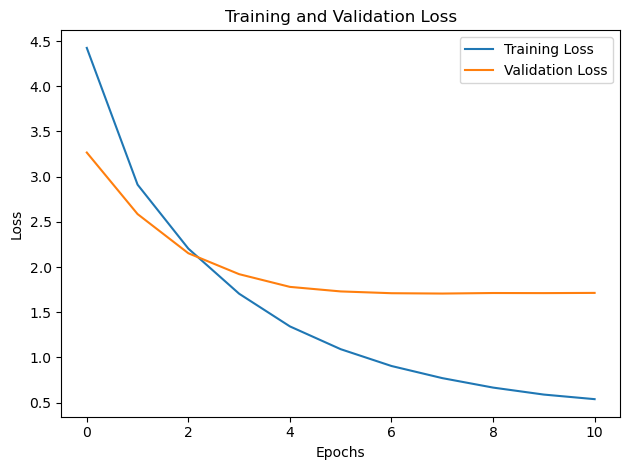

In [120]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.plot(loss, label = 'Training Loss')
plt.plot(val_loss, label = 'Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

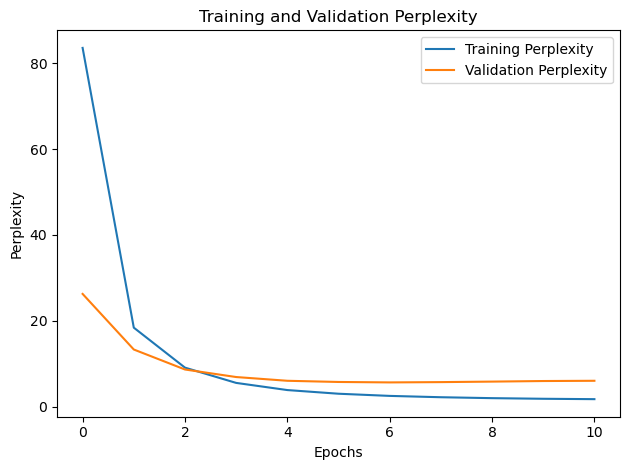

In [121]:
perplexity = history.history['perplexity']
val_perplexity = history.history['val_perplexity']

plt.plot(perplexity, label = 'Training Perplexity')
plt.plot(val_perplexity, label = 'Validation Perplexity')
plt.title('Training and Validation Perplexity')
plt.xlabel('Epochs')
plt.ylabel('Perplexity')
plt.legend()
plt.tight_layout()
plt.show()

In [122]:
for eng, urdu in test[:12]:
    print(f'EN    : {eng}')
    print(f'Model : {translate(eng)}')
    print(f'Truth : {urdu}')
    print()

EN    : you are so stupid


d:\conda_envs\ai_two\Lib\site-packages\keras\src\ops\nn.py:959: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


Model : آپ بہت بیوقوف ہیں
Truth : تم بہت بیوقوف ہو

EN    : zain seems harmless
Model : زین بے ضرر لگتا ہے
Truth : زین بے ضرر لگتا ہے۔

EN    : how do you do
Model : آپ کیسے کرتے ہیں
Truth : آپ کیسے ہیں

EN    : is zain ready
Model : زین تیار ہے
Truth : زین تیار ہے

EN    : did you help tom
Model : کیا آپ نے ٹام کی مدد کی؟
Truth : کیا آپ نے ٹام کی مدد کی؟

EN    : i have been to rome
Model : میں روم کود گیا ہوں
Truth : میں روم گیا ہوں۔

EN    : another day passed
Model : ایک بار گزر گیا
Truth : ایک اور دن گزر گیا

EN    : who wrote this
Model : یہ کس نے لکھا
Truth : یہ کس نے لکھا

EN    : i hate myself
Model : مجھے اپنے آپ سے نفرت ہے۔
Truth : مجھے خود سے نفرت ہے

EN    : two chapattis were not enough for me
Model : دو اور میری بہن نہیں تھے۔
Truth : دو چپاتیاں میرے لیے کافی نہیں تھیں۔

EN    : have some
Model : کچھ
Truth : کچھ

EN    : its just a fantasy
Model : یہ صرف ایک طریقہ ہے
Truth : یہ صرف ایک فنتاسی ہے



In [123]:
N_TEST = 300
references, hypotheses = [], []
exact_matches = 0

for i, (eng, urdu) in enumerate(test[:N_TEST]):
    hyp = translate(eng)
    references.append([urdu])
    hypotheses.append(hyp)
    exact_matches += (hyp == urdu)
    if (i + 1) % 100 == 0:
        print(f'   decoded {i + 1}/{N_TEST} sentences…')

print()
print(f'=== TEST RESULTS on {N_TEST} unseen sentences ===')
for name, order in [('BLEU-2 (corpus)', 2), ('BLEU-4 (corpus)', 4)]:
    bleu = keras_hub.metrics.Bleu(max_order=order)
    bleu.update_state(references, hypotheses)
    print(f'{name:17s}: {float(bleu.result()) * 100:.1f} / 100')
print(f'Perfect matches  : {exact_matches}/{N_TEST} ({exact_matches / N_TEST:.0%})')

   decoded 100/300 sentences…
   decoded 200/300 sentences…
   decoded 300/300 sentences…

=== TEST RESULTS on 300 unseen sentences ===
BLEU-2 (corpus)  : 55.0 / 100
BLEU-4 (corpus)  : 41.9 / 100
Perfect matches  : 64/300 (21%)
